# Subject Visual Design Matrix (VDM) Generator

Creates subject-specific VDM files for the pRF fit.

**Specifications:**
- Input: .mat stimulus files (Bars A, Bars B), current VDM files (Rings, Wedges)
- Bars B: sub-14, sub-17 (all runs), sub-05 (BarsRightEye run-01)
- sub-16: BarsLeftEye run-01, BarsRightEye run-01 and run-02 rebuilt from the sweeps of Bars A
- Concatenation: Bars run-01, Bars run-02, Rings, Wedges
- Output: 50×50 VDM saved as derivatives/vdm/sub-XX/sub-XX_task-{task}_vdm.npy

In [1]:
# General imports
import os
import math
import tempfile
import glob
import cv2
import numpy as np
import pandas as pd
import nibabel as nb
import scipy.io as sio
import matplotlib.pyplot as plt

/var/folders/60/q71xm4hx45x3db5d6mzl8r4h0000gn/T/ipykernel_1485/3348788121.py:8: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
# Define parameters
main_dir = '/Users/uriel/disks/meso_shared/amblyo7T_prf/'
input_dir = os.path.join(main_dir, 'derivatives/vdm/original/')
output_dir = os.path.join(main_dir, 'derivatives/vdm/')
pp_dir = os.path.join(main_dir, 'derivatives/pp_data/')
save_vdm = True  # set to True to save the subject VDM files

# VDM settings
vdm_width = 50
vdm_height = 50
TR = 2  # seconds
n_images = 120

# Stimulus files
bars_A_fn = os.path.join(input_dir, 'Bars.mat')
bars_B_fn = os.path.join(main_dir, 'sourcedata/C/jp/cond-1-stim-3.mat')

# Subjects and tasks
subjects = ['sub-{:02d}'.format(i) for i in range(1, 22) if i != 7]
task_names = ['BarsBarsRingsWedgesRightEye', 'BarsBarsRingsWedgesLeftEye',
              'BarsBarsRightEye', 'BarsBarsLeftEye',
              'RingsWedgesRightEye', 'RingsWedgesLeftEye']
bars_runs = ['BarsLeftEye_run-01', 'BarsLeftEye_run-02', 'BarsRightEye_run-01', 'BarsRightEye_run-02']

# Bars sequence of each run
bars_seq = {subject: {run: 'A' for run in bars_runs} for subject in subjects}
for subject in ['sub-14', 'sub-17']:
    bars_seq[subject] = {run: 'B' for run in bars_runs}
bars_seq['sub-05']['BarsRightEye_run-01'] = 'B'
for run in ['BarsLeftEye_run-01', 'BarsRightEye_run-01', 'BarsRightEye_run-02']:
    bars_seq['sub-16'][run] = 'sub-16_{}'.format(run)

# sub-16 sequences (sweep direction, start TR); remaining TRs are blank
sub16_sweeps = {
    'BarsLeftEye_run-01': [('90+', 5), ('0+', 17), ('45+', 34), ('135-', 47), ('45-', 59),
                           ('135+', 71), ('90-', 83), ('135-', 95), ('0-', 107)],
    'BarsRightEye_run-01': [('135-', 5), ('0+', 17), ('135-', 29), ('45-', 41), ('135+', 53),
                            ('90+', 65), ('0-', 82), ('45+', 94), ('90-', 107)],
    'BarsRightEye_run-02': [('135-', 5), ('0-', 17), ('45+', 29), ('135+', 41), ('45-', 53),
                            ('135-', 71), ('90+', 83), ('90-', 95), ('0+', 107)]}

# pRF fit used to check the designs against the data
prf_check_folder = 'prfmodel_old'

In [3]:
# Convert .mat stimulus to VDM (same steps as create_prf_videos and create_vdm_files)
def load_mat(fn):
    mat = sio.loadmat(fn)
    return mat['s']['im'][0, 0]

def pad_image(image):
    frame = (image * 255).astype(np.uint8).T
    top_margin = np.zeros((12, frame.shape[1]), dtype=np.uint8)
    bottom_margin = np.zeros((13, frame.shape[1]), dtype=np.uint8)
    return np.vstack([top_margin, frame, bottom_margin])

def mat_to_vdm(s_im, video_fn):
    # write video (60 Hz, 2 s per image)
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(video_fn, fourcc, 60, (102, 102), False)
    for i in range(s_im.shape[2]):
        frame_padded = pad_image(s_im[:, :, i])
        for _ in range(120):
            out.write(frame_padded)
    out.release()

    # read video and sample one frame per TR
    vdm_mat = np.zeros((vdm_width, vdm_height, s_im.shape[2]))
    cap = cv2.VideoCapture(video_fn)
    vid_idx, vdm_idx = 0, 0
    while cap.isOpened():
        ret, vid_frame = cap.read()
        if not ret:
            break
        if np.mod(vid_idx, 120) == 0 and vdm_idx < s_im.shape[2]:
            gray_mat = cv2.cvtColor(vid_frame, cv2.COLOR_BGR2GRAY)
            binary_mat = (gray_mat > 5).astype(np.uint8)
            vdm_mat[..., vdm_idx] = cv2.resize(binary_mat, dsize=(vdm_width, vdm_height),
                                               interpolation=cv2.INTER_NEAREST)
            vdm_idx += 1
        vid_idx += 1
    cap.release()
    os.remove(video_fn)
    return vdm_mat

# Load current VDM
current_vdm = {task_name: np.load(os.path.join(output_dir, 'task-{}_vdm.npy'.format(task_name)))
               for task_name in task_names}

# Bars A and B
bars_A_im = load_mat(bars_A_fn)
bars_B_im = load_mat(bars_B_fn)
vdm_A = mat_to_vdm(bars_A_im, os.path.join(tempfile.gettempdir(), 'tmp_A_60hz.mp4'))
vdm_B = mat_to_vdm(bars_B_im, os.path.join(tempfile.gettempdir(), 'tmp_B_60hz.mp4'))

# Bars A taken from the current VDM, Bars B converted from its .mat file
n_diff = int((vdm_A != current_vdm['BarsBarsRingsWedgesLeftEye'][..., :n_images]).sum())
print("Bars A conversion vs current VDM: {} different pixels out of {}".format(n_diff, vdm_A.size))
vdm_A = current_vdm['BarsBarsRingsWedgesLeftEye'][..., :n_images].copy()
print("  ✓ Bars A: current VDM")
print("  ✓ Bars B: converted from {}".format(bars_B_fn))

Bars A conversion vs current VDM: 1 different pixels out of 300000
  ✓ Bars A: current VDM
  ✓ Bars B: converted from /Users/uriel/disks/meso_shared/amblyo7T_prf/sourcedata/C/jp/cond-1-stim-3.mat


In [4]:
# Check current VDM content
for eye in ['LeftEye', 'RightEye']:
    vdm = current_vdm['BarsBarsRingsWedges{}'.format(eye)]
    print("\n=== {} ===".format(eye))
    print("  Bars run-01 = A: {}".format(np.array_equal(vdm[..., :120], vdm_A)))
    print("  Bars run-02 = A: {}".format(np.array_equal(vdm[..., 120:240], vdm_A)))
    print("  BarsBars = Bars blocks: {}".format(np.array_equal(current_vdm['BarsBars{}'.format(eye)], vdm[..., :240])))
    print("  RingsWedges = Rings/Wedges blocks: {}".format(np.array_equal(current_vdm['RingsWedges{}'.format(eye)], vdm[..., 240:])))
    for folder in ['', 'real_rings-wedges/', 'bars_to_rings-wedges/']:
        for stim, block in [('Rings', vdm[..., 240:360]), ('Wedges', vdm[..., 360:480])]:
            fn = os.path.join(output_dir, folder, 'task-{}{}_vdm.npy'.format(stim, eye))
            if os.path.exists(fn):
                same = np.array_equal(np.load(fn), block)
                print("  {}task-{}{}_vdm.npy = current block: {}".format(folder, stim, eye, same))


=== LeftEye ===
  Bars run-01 = A: True
  Bars run-02 = A: True
  BarsBars = Bars blocks: True
  RingsWedges = Rings/Wedges blocks: True
  task-RingsLeftEye_vdm.npy = current block: True
  task-WedgesLeftEye_vdm.npy = current block: True
  real_rings-wedges/task-RingsLeftEye_vdm.npy = current block: True
  real_rings-wedges/task-WedgesLeftEye_vdm.npy = current block: True
  bars_to_rings-wedges/task-RingsLeftEye_vdm.npy = current block: False
  bars_to_rings-wedges/task-WedgesLeftEye_vdm.npy = current block: False

=== RightEye ===
  Bars run-01 = A: True
  Bars run-02 = A: True
  BarsBars = Bars blocks: True
  RingsWedges = Rings/Wedges blocks: True
  task-RingsRightEye_vdm.npy = current block: True
  task-WedgesRightEye_vdm.npy = current block: True
  real_rings-wedges/task-RingsRightEye_vdm.npy = current block: True
  real_rings-wedges/task-WedgesRightEye_vdm.npy = current block: True
  bars_to_rings-wedges/task-RingsRightEye_vdm.npy = current block: False
  bars_to_rings-wedges/ta

In [5]:
# Create sub-16 bars VDM from the sweeps of Bars A
def frame_orientation(frame):
    rows, cols = np.meshgrid(np.arange(vdm_height) - 24.5, np.arange(vdm_width) - 24.5, indexing='ij')
    x, y = cols, -rows
    mask = frame > 0
    if mask.sum() < 3:
        return None, np.nan
    best = None
    for angle in [0, 45, 90, 135]:
        proj = x[mask] * np.cos(np.deg2rad(angle)) + y[mask] * np.sin(np.deg2rad(angle))
        if best is None or proj.std() < best[0]:
            best = (proj.std(), angle, proj.mean())
    return best[1], best[2]

# start image of each sweep direction in Bars A
sweep_start = {}
t = 0
while t < n_images:
    angle, pos = frame_orientation(vdm_A[..., t])
    if angle is None:
        t += 1
        continue
    u = t + 1
    while u < n_images and frame_orientation(vdm_A[..., u])[0] == angle and u - t < 12:
        u += 1
    direction = '{}{}'.format(angle, '+' if frame_orientation(vdm_A[..., u - 1])[1] > pos else '-')
    if u - t == 12 and direction not in sweep_start:
        sweep_start[direction] = t
    t = u
print("Sweeps in Bars A: {}".format(sweep_start))

vdm_sub16 = {}
for run, sweeps in sub16_sweeps.items():
    vdm = np.zeros((vdm_height, vdm_width, n_images))
    for direction, start in sweeps:
        n = min(12, n_images - start)
        vdm[..., start:start + n] = vdm_A[..., sweep_start[direction]:sweep_start[direction] + n]
    vdm_sub16['sub-16_{}'.format(run)] = vdm
    directions = [d for d, _ in sweeps]
    print("  ✓ {}: {} directions, repeated: {}".format(
        run, len(set(directions)), [d for d in set(directions) if directions.count(d) > 1]))

def get_bars_vdm(subject, run):
    seq = bars_seq[subject][run]
    if seq == 'A':
        return vdm_A
    elif seq == 'B':
        return vdm_B
    return vdm_sub16[seq]

Sweeps in Bars A: {'135+': 6, '90+': 18, '45-': 35, '0+': 47, '135-': 59, '0-': 71, '45+': 83, '90-': 95}
  ✓ BarsLeftEye_run-01: 8 directions, repeated: ['135-']
  ✓ BarsRightEye_run-01: 8 directions, repeated: ['135-']
  ✓ BarsRightEye_run-02: 8 directions, repeated: ['135-']


In [6]:
# Create subject VDM
def run_fn(subject, task, hemi='L'):
    return os.path.join(pp_dir, subject, 'fsnative/func/fmriprep_dct_psc',
                        '{}_ses-01_task-{}_hemi-{}_space-fsnative_fmriprep_dct_psc_bold.func.gii'.format(subject, task, hemi))

subject_vdm, checks = {}, []
for subject in subjects:
    subject_vdm[subject] = {}
    for eye in ['LeftEye', 'RightEye']:
        bars_01 = get_bars_vdm(subject, 'Bars{}_run-01'.format(eye))
        bars_02 = get_bars_vdm(subject, 'Bars{}_run-02'.format(eye))
        rings_wedges = current_vdm['RingsWedges{}'.format(eye)]
        subject_vdm[subject]['BarsBarsRingsWedges{}'.format(eye)] = np.concatenate([bars_01, bars_02, rings_wedges], axis=2)
        subject_vdm[subject]['BarsBars{}'.format(eye)] = np.concatenate([bars_01, bars_02], axis=2)
        subject_vdm[subject]['RingsWedges{}'.format(eye)] = rings_wedges.copy()

    vdm = subject_vdm[subject]
    all_A = all(bars_seq[subject][run] == 'A' for run in bars_runs)
    checks.append({'subject': subject,
                   'bars': ' '.join(bars_seq[subject][run] if bars_seq[subject][run] in ['A', 'B'] else 'rec'
                                    for run in bars_runs),
                   'runs found': all(os.path.exists(run_fn(subject, task)) for task in bars_runs +
                                     ['{}{}_run-01'.format(s, e) for s in ['Rings', 'Wedges'] for e in ['LeftEye', 'RightEye']]),
                   'shapes': all(vdm[t].shape == current_vdm[t].shape for t in task_names),
                   'binary': all(set(np.unique(vdm[t])) <= {0, 1} for t in task_names),
                   'rings/wedges': all(np.array_equal(vdm['BarsBarsRingsWedges{}'.format(e)][..., 240:],
                                                      current_vdm['RingsWedges{}'.format(e)]) for e in ['LeftEye', 'RightEye']),
                   'same as current': all(np.array_equal(vdm[t], current_vdm[t]) for t in task_names),
                   'all A': all_A})
checks = pd.DataFrame(checks).set_index('subject')
checks['ok'] = checks['shapes'] & checks['binary'] & checks['rings/wedges'] & (checks['same as current'] == checks['all A'])
print(checks.to_string())
print("\nAll checks passed: {}".format(checks['ok'].all()))

                  bars  runs found  shapes  binary  rings/wedges  same as current  all A    ok
subject                                                                                       
sub-01         A A A A        True    True    True          True             True   True  True
sub-02         A A A A        True    True    True          True             True   True  True
sub-03         A A A A        True    True    True          True             True   True  True
sub-04         A A A A        True    True    True          True             True   True  True
sub-05         A A B A        True    True    True          True            False  False  True
sub-06         A A A A        True    True    True          True             True   True  True
sub-08         A A A A        True    True    True          True             True   True  True
sub-09         A A A A        True    True    True          True             True   True  True
sub-10         A A A A        True    True    True

In [7]:
# Check bars VDM against data (RingsWedges pRF of each eye)
screen_deg = 2 * np.degrees(np.arctan(50.6 / (2 * 242)))
pix_deg = screen_deg / vdm_width
rows, cols = np.meshgrid(np.arange(vdm_height) - 24.5, np.arange(vdm_width) - 24.5, indexing='ij')
x_deg, y_deg = (cols * pix_deg).ravel(), (-rows * pix_deg).ravel()

t_hrf = np.arange(0, 32, TR)
gamma = lambda a: t_hrf ** (a - 1) * np.exp(-t_hrf) / math.gamma(a)
hrf = gamma(6) - gamma(16) / 6
hrf /= hrf.sum()

def zscore(a):
    return (a - a.mean(0)) / (a.std(0) + 1e-9)

def prf_corr(vdm, data, x0, y0, size, n):
    gauss = np.exp(-((x_deg[:, None] - x0) ** 2 + (y_deg[:, None] - y0) ** 2) / (2 * size ** 2))
    drive = np.clip(np.moveaxis(vdm, -1, 0).reshape(n_images, -1) @ gauss, 0, None) ** n
    pred = np.apply_along_axis(lambda v: np.convolve(v, hrf)[:n_images], 0, drive)
    best = -np.inf
    for shift in range(-2, 3):
        pred_shift = np.roll(pred, shift, axis=0)
        best = max(best, float(np.median((zscore(pred_shift) * zscore(data)).mean(0))))
    return best

data_check = []
for subject in subjects:
    roi_fns = [glob.glob(os.path.join(pp_dir, subject, 'fsnative/rois',
                                      '{}_hemi-{}_fmriprep_dct_*_rois-group-mmp.func.gii'.format(subject, hemi))) for hemi in ['L', 'R']]
    if not all(roi_fns):
        print("{}: no ROI file".format(subject))
        continue
    roi = np.concatenate([nb.load(fn[0]).darrays[0].data for fn in roi_fns])
    for eye in ['LeftEye', 'RightEye']:
        deriv_fns = [os.path.join(pp_dir, subject, 'fsnative', prf_check_folder, 'prf_derivatives',
                                  '{}_task-RingsWedges{}_hemi-{}_fmriprep_dct_psc_concat_prf-css_deriv.func.gii'.format(subject, eye, hemi))
                     for hemi in ['L', 'R']]
        if not all(os.path.exists(fn) for fn in deriv_fns):
            print("{} {}: no RingsWedges pRF".format(subject, eye))
            continue
        deriv = np.hstack([np.vstack([d.data for d in nb.load(fn).darrays]) for fn in deriv_fns])
        for run in ['Bars{}_run-01'.format(eye), 'Bars{}_run-02'.format(eye)]:
            if not os.path.exists(run_fn(subject, run)):
                continue
            data = []
            for hemi in ['L', 'R']:
                d = np.vstack([a.data for a in nb.load(run_fn(subject, run, hemi)).darrays])
                data.append(d if d.shape[0] == n_images else d.T)
            data = np.hstack(data)
            vert = np.where((deriv[0] > 0.2) & (deriv[1] < 6) & np.isin(roi, [1, 2, 3]) &
                            np.isfinite(data).all(0) & (data.std(0) > 0))[0]
            params = (deriv[7][vert], deriv[8][vert], np.clip(deriv[4][vert], 0.2, None), np.clip(deriv[11][vert], 0.05, 1))
            r_sel = prf_corr(get_bars_vdm(subject, run), data[:, vert], *params)
            r_A = prf_corr(vdm_A, data[:, vert], *params)
            r_B = prf_corr(vdm_B, data[:, vert], *params)
            data_check.append({'subject': subject, 'run': run, 'bars': bars_seq[subject][run].split('_')[0],
                               'r selected': r_sel, 'r A': r_A, 'r B': r_B, 'ok': r_sel >= max(r_A, r_B) - 0.01})
    print("  ✓ {}".format(subject))
data_check = pd.DataFrame(data_check)
print(data_check.round(3).to_string())
print("\nAll runs ok: {}".format(data_check['ok'].all()))

  ✓ sub-01
  ✓ sub-02
  ✓ sub-03
  ✓ sub-04
  ✓ sub-05
  ✓ sub-06
  ✓ sub-08
  ✓ sub-09
  ✓ sub-10
  ✓ sub-11
  ✓ sub-12
  ✓ sub-13
  ✓ sub-14
sub-15 LeftEye: no RingsWedges pRF
sub-15 RightEye: no RingsWedges pRF
  ✓ sub-15
  ✓ sub-16
  ✓ sub-17
  ✓ sub-18
  ✓ sub-19
  ✓ sub-20
sub-21 LeftEye: no RingsWedges pRF
  ✓ sub-21
   subject                  run    bars  r selected    r A    r B    ok
0   sub-01   BarsLeftEye_run-01       A       0.616  0.616  0.124  True
1   sub-01   BarsLeftEye_run-02       A       0.575  0.575  0.232  True
2   sub-01  BarsRightEye_run-01       A       0.594  0.594  0.209  True
3   sub-01  BarsRightEye_run-02       A       0.598  0.598  0.190  True
4   sub-02   BarsLeftEye_run-01       A       0.619  0.619  0.190  True
5   sub-02   BarsLeftEye_run-02       A       0.586  0.586  0.172  True
6   sub-02  BarsRightEye_run-01       A       0.603  0.603  0.154  True
7   sub-02  BarsRightEye_run-02       A       0.609  0.609  0.155  True
8   sub-03   BarsLeftEye_r

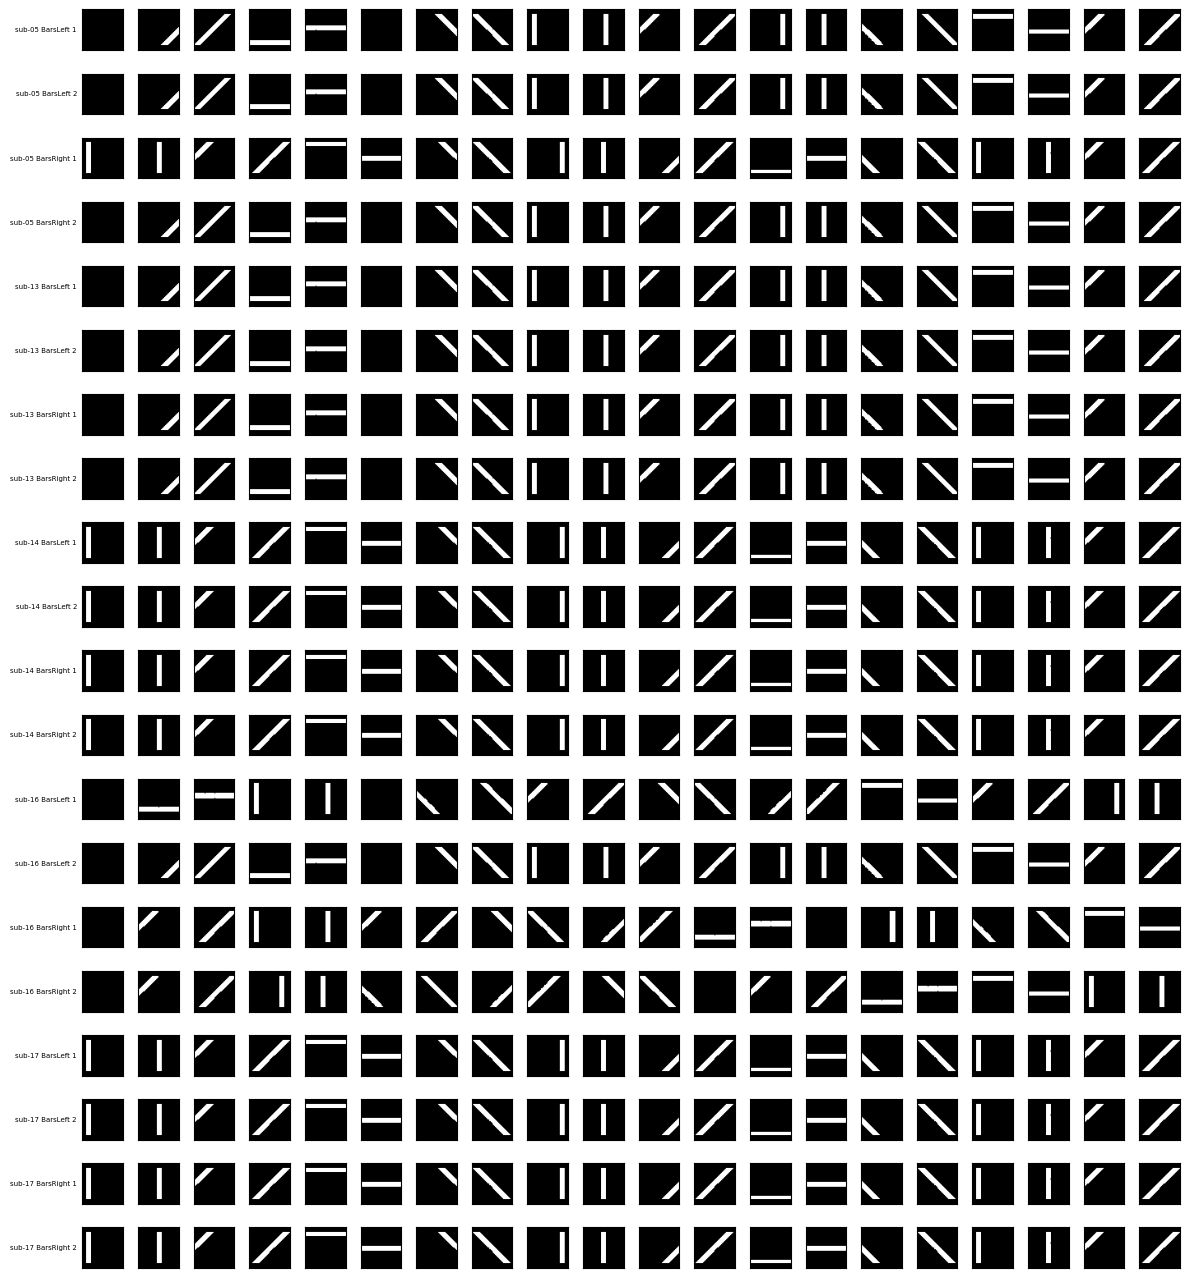

In [8]:
# Plot bars VDM of subjects with specific sequences
plot_subjects = ['sub-05', 'sub-13', 'sub-14', 'sub-16', 'sub-17']
plot_tr = list(range(0, n_images, 6))
fig, axes = plt.subplots(len(plot_subjects) * 4, len(plot_tr), figsize=(len(plot_tr) * 0.6, len(plot_subjects) * 4 * 0.65))
for i, subject in enumerate(plot_subjects):
    for j, run in enumerate(bars_runs):
        vdm = get_bars_vdm(subject, run)
        for k, tr in enumerate(plot_tr):
            ax = axes[i * 4 + j, k]
            ax.imshow(vdm[..., tr], cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[i * 4 + j, 0].set_ylabel('{} {}'.format(subject, run.replace('Eye_run-0', ' ')), fontsize=5,
                                      rotation=0, ha='right', va='center')
plt.tight_layout()
plt.show()

In [9]:
# Save subject VDM
if save_vdm:
    assert checks['ok'].all() and data_check['ok'].all(), "Checks failed, VDM not saved"
    for subject in subjects:
        subject_dir = os.path.join(output_dir, subject)
        os.makedirs(subject_dir, exist_ok=True)
        for task_name in task_names:
            vdm_fn = os.path.join(subject_dir, '{}_task-{}_vdm.npy'.format(subject, task_name))
            np.save(vdm_fn, subject_vdm[subject][task_name])
        print("  ✓ Saved {}".format(subject_dir))
else:
    print("save_vdm = False, nothing saved")

  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-01
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-02
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-03
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-04
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-05
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-06
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-08
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-09
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-10
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-11
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-12
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-13
  ✓ Saved /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/sub-14